# 04 — Residual diagnostics and the ARCH/GARCH decision

**Milestone M6.** Two questions:

1. **Are the selected models adequate?** Are their one-step residuals unbiased, free of leftover autocorrelation, and how are they distributed?
2. **Is there conditional heteroscedasticity (volatility clustering)** strong enough to justify a GARCH model for the prediction intervals?

**Scope.** Both joint-best families from M5 (ETS and SARIMA) are refit with the exact specification the backtest chose at each of the 4 origins. That is 8 products × 2 families × 4 origins = 64 fits. The "selected" model per product is the family with the lower mean RMSSE.

**Tests**

| Check | Test | Note |
|---|---|---|
| Bias | one-sample t-test of mean residual = 0 | |
| Autocorrelation | Ljung–Box at lags 7, 14, 21 | Degrees of freedom reduced by the number of fitted ARMA/smoothing parameters |
| Effect size | largest absolute residual ACF, lags 1–21 | With ~700 points even tiny correlations become "significant" |
| Distribution | Jarque–Bera, skewness, excess kurtosis, QQ plot | Descriptive only: normality is not required for point forecasts |
| ARCH effects | Engle's ARCH-LM test, lag 7 | Pre-specified gate for GARCH |

**GARCH gate (pre-specified in DESIGN.md):** fit GARCH(1,1) only if ARCH-LM p < 0.05 and the series has ≤ 30% zero days. GARCH never changes the point forecast. It rescales the mean model's intervals by predicted volatility relative to its long-run level. It is kept only if that improves the held-out **interval score** (Winkler score: width plus a penalty for misses; lower is better).

Code: `src/optichain/residual_checks.py`, `scripts/run_residuals.py`.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

from optichain import plots as P
from optichain.config import PROJECT_ROOT, load_config

P.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
cfg = load_config()
ITEMS, LAST = cfg.series.items, max(cfg.forecast.origins)
M = PROJECT_ROOT / "reports" / "metrics"
diag = pd.read_csv(M / "residual_diagnostics.csv")
garch = pd.read_csv(M / "garch_evaluation.csv")
decision = pd.read_csv(M / "garch_decision.csv")
sel = diag[diag["selected"]]
FIG = PROJECT_ROOT / "reports" / "figures" / "residuals"
print(f"{len(diag)} refits; selected family per item:", sel.groupby("item_id")["model"].first().to_dict())

64 refits; selected family per item: {'FOODS_3_203': 'ets', 'FOODS_3_242': 'sarima', 'FOODS_3_586': 'ets', 'HOBBIES_1_030': 'ets', 'HOBBIES_1_189': 'ets', 'HOUSEHOLD_1_046': 'ets', 'HOUSEHOLD_1_447': 'ets', 'HOUSEHOLD_1_469': 'sarima'}


## 1. Residual adequacy of the selected models

In [2]:
cols = ["model", "spec", "resid_mean", "mean_p", "lb_p_7", "lb_p_14", "lb_p_21", "max_abs_acf",
        "skew", "excess_kurtosis", "jb_p", "arch_lm_p"]
display(sel[sel["origin_d"] == LAST].set_index("item_id").loc[ITEMS, cols])

,model,spec,resid_mean,mean_p,lb_p_7,lb_p_14,lb_p_21,max_abs_acf,skew,excess_kurtosis,jb_p,arch_lm_p
item_id,,,,,,,,,,,,
FOODS_3_586,ets,"ETS(A,N,A)",2.161e-02,0.954,0.013,0.091,0.303,0.084,-0.073,0.530,1.009e-02,1.987e-02
HOUSEHOLD_1_447,ets,"ETS(A,N,A)",1.112e-01,0.419,0.171,0.534,0.457,0.067,0.472,0.291,3.541e-07,2.356e-04
FOODS_3_203,ets,"ETS(A,N,A)",-7.124e-03,0.934,0.046,0.268,0.232,0.083,0.532,0.482,9.905e-10,2.689e-04
HOBBIES_1_189,ets,"ETS(A,N,N)",2.027e-01,0.472,0.016,0.128,0.442,0.079,1.751,4.378,2.422e-208,5.767e-02
HOBBIES_1_030,ets,"ETS(A,N,A)",-6.033e-03,0.976,0.096,0.333,0.449,0.080,1.886,8.159,0.000e+00,8.339e-01
HOUSEHOLD_1_469,sarima,"ARIMA(0,1,1)(1,0,1)[7]",-4.321e-02,0.281,0.310,0.751,0.840,0.060,1.083,1.674,9.745e-49,1.122e-01
FOODS_3_242,sarima,"ARIMA(0,0,0)(1,0,1)[7]",-1.067e-03,0.977,0.869,0.929,0.953,0.061,1.361,2.099,1.510e-76,8.066e-01
HOUSEHOLD_1_046,ets,"ETS(A,N,A)",-5.758e-04,0.992,0.102,0.306,0.706,0.082,2.271,9.033,0.000e+00,8.897e-01


In [3]:
print("Ljung-Box p-value at lag 7, selected model, every origin:")
display(sel.pivot(index="item_id", columns="origin_d", values="lb_p_7").loc[ITEMS]
        .style.format("{:.3f}").map(lambda v: "background-color:#f8d7d6" if v < 0.05 else ""))
print("Largest |residual ACF| (lags 1-21):")
display(sel.pivot(index="item_id", columns="origin_d", values="max_abs_acf").loc[ITEMS].round(3))
summary = pd.Series({
    "fits with unbiased residuals": f"{int(sel['unbiased'].sum())} / {len(sel)}",
    "fits passing Ljung-Box at all lags": f"{int(sel['no_autocorrelation'].sum())} / {len(sel)}",
    "largest |ACF| in any fit": f"{sel['max_abs_acf'].max():.3f}",
    "Ljung-Box lag-7 rejections, ETS (all items)": f"{(diag[diag.model == 'ets']['lb_p_7'] < 0.05).mean():.0%}",
    "Ljung-Box lag-7 rejections, SARIMA (all items)": f"{(diag[diag.model == 'sarima']['lb_p_7'] < 0.05).mean():.0%}",
})
display(summary.to_frame("value"))

Ljung-Box p-value at lag 7, selected model, every origin:


origin_d,1800,1828,1856,1885
item_id,,,,
FOODS_3_586,0.015,0.029,0.021,0.013
HOUSEHOLD_1_447,0.021,0.012,0.040,0.171
FOODS_3_203,0.062,0.046,0.053,0.046
HOBBIES_1_189,0.063,0.057,0.019,0.016
HOBBIES_1_030,0.038,0.039,0.053,0.096
HOUSEHOLD_1_469,0.139,0.124,0.217,0.310
FOODS_3_242,0.706,0.746,0.811,0.869
HOUSEHOLD_1_046,0.035,0.043,0.057,0.102


Largest |residual ACF| (lags 1-21):


origin_d,1800,1828,1856,1885
item_id,,,,
FOODS_3_586,0.096,0.084,0.082,0.084
HOUSEHOLD_1_447,0.089,0.088,0.085,0.067
FOODS_3_203,0.079,0.080,0.080,0.083
HOBBIES_1_189,0.086,0.094,0.089,0.079
HOBBIES_1_030,0.080,0.078,0.078,0.080
HOUSEHOLD_1_469,0.056,0.062,0.060,0.060
FOODS_3_242,0.049,0.059,0.059,0.061
HOUSEHOLD_1_046,0.080,0.085,0.089,0.082


,value
fits with unbiased residuals,32 / 32
fits passing Ljung-Box at all lags,17 / 32
largest |ACF| in any fit,0.096
"Ljung-Box lag-7 rejections, ETS (all items)",50%
"Ljung-Box lag-7 rejections, SARIMA (all items)",38%


**Interpretation**

- **Bias: none.** The residual mean is statistically indistinguishable from zero in every one of the 32 selected fits (all t-test p > 0.05). The models do not systematically over- or under-forecast in-sample.
- **Autocorrelation is statistically detectable but practically small.**
  - Ljung–Box rejects at lag 7 for about half the selected fits, most consistently for FOODS_3_586 (p = 0.013–0.029 at every origin), FOODS_3_203 and HOBBIES_1_189.
  - Yet the largest residual autocorrelation in any fit is 0.096, and with ~700 observations the 95% significance band is about ±0.074. A correlation of 0.1 explains about 1% of the residual variance.
  - The leftover structure is mostly at lags 1, 5 and 7. The additive weekly seasonal pattern in ETS is fixed, while the real weekend effect varies a little from week to week.
- **SARIMA residuals are slightly cleaner** (38% lag-7 rejections vs 50% for ETS), as expected: its seasonal AR/MA terms adapt to the weekly pattern. ETS still forecasts slightly better out-of-sample (notebook 03), so the small in-sample autocorrelation does not translate into worse forecasts.
- **Remedies considered but not adopted:**
  - Larger AR orders or a second seasonal lag would remove a correlation of ≤ 0.1 at the cost of more parameters. M5 already showed that extra SARIMA flexibility does not beat ETS out-of-sample.
  - This is recorded as a known, quantified limitation rather than chasing in-sample whiteness.
- **Distribution:**
  - The high-volume FOODS_3_586 has near-normal residuals (excess kurtosis 0.5; see the QQ plot below).
  - The spiky and lumpy products (both HOBBIES items, HOUSEHOLD_1_046) have heavy tails (excess kurtosis 4–9). The intermittent products are moderately heavy-tailed (1.7–2.1). Jarque–Bera rejects normality everywhere.
  - Normality is not needed for point forecasts. But the normal-theory intervals will be **too narrow in the tails** for heavy-tailed products, which is relevant to safety-stock sizing in M7.

## 2. Residual plots

### FOODS_3_586 · ETS(A,N,A): the best-behaved series

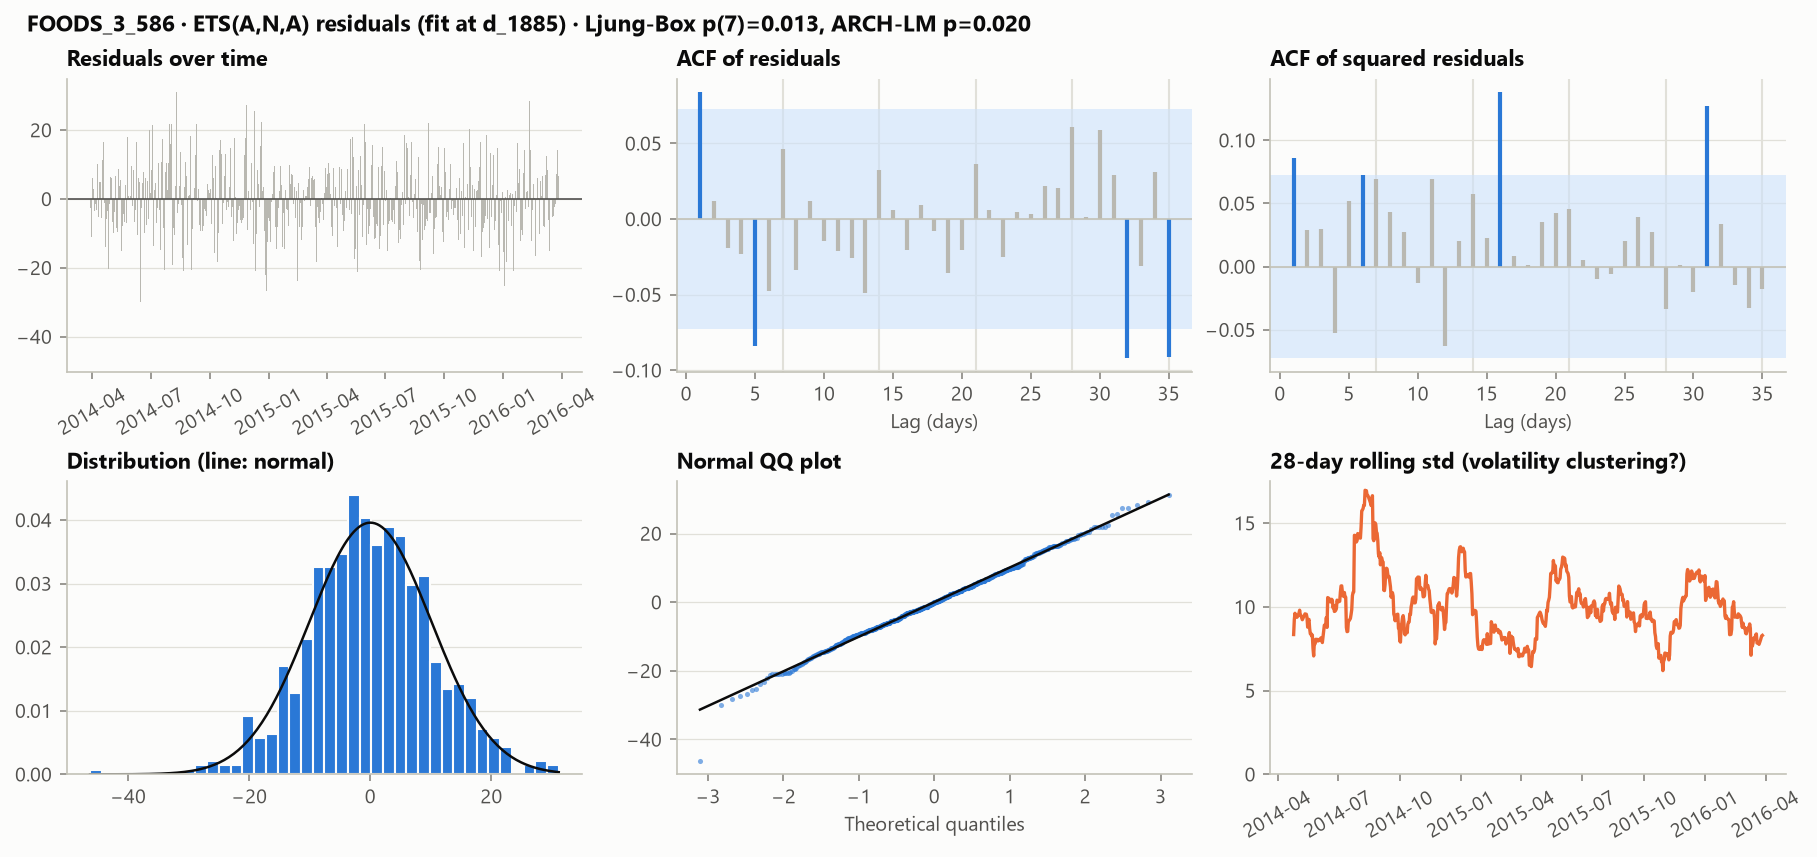

In [4]:
display(Image(filename=str(FIG / "FOODS_3_586_ets.png"), width=1100))

- Residuals are centred on zero with no visible trend, and the QQ plot follows the normal line almost exactly.
- Residual ACF: small spikes at lags 1, 5 and 32–35, all within about ±0.09.
- Squared-residual ACF: a few spikes (lags 1, 6, 16, 31). This is the pattern the ARCH-LM test picks up.
- The 28-day rolling std peaks in **summer 2014**. That looks like *seasonal* volatility (busier periods are more variable) rather than the shock-driven clustering GARCH is designed for.

### HOBBIES_1_030 · ETS(A,N,A): heavy tails, no ARCH effects

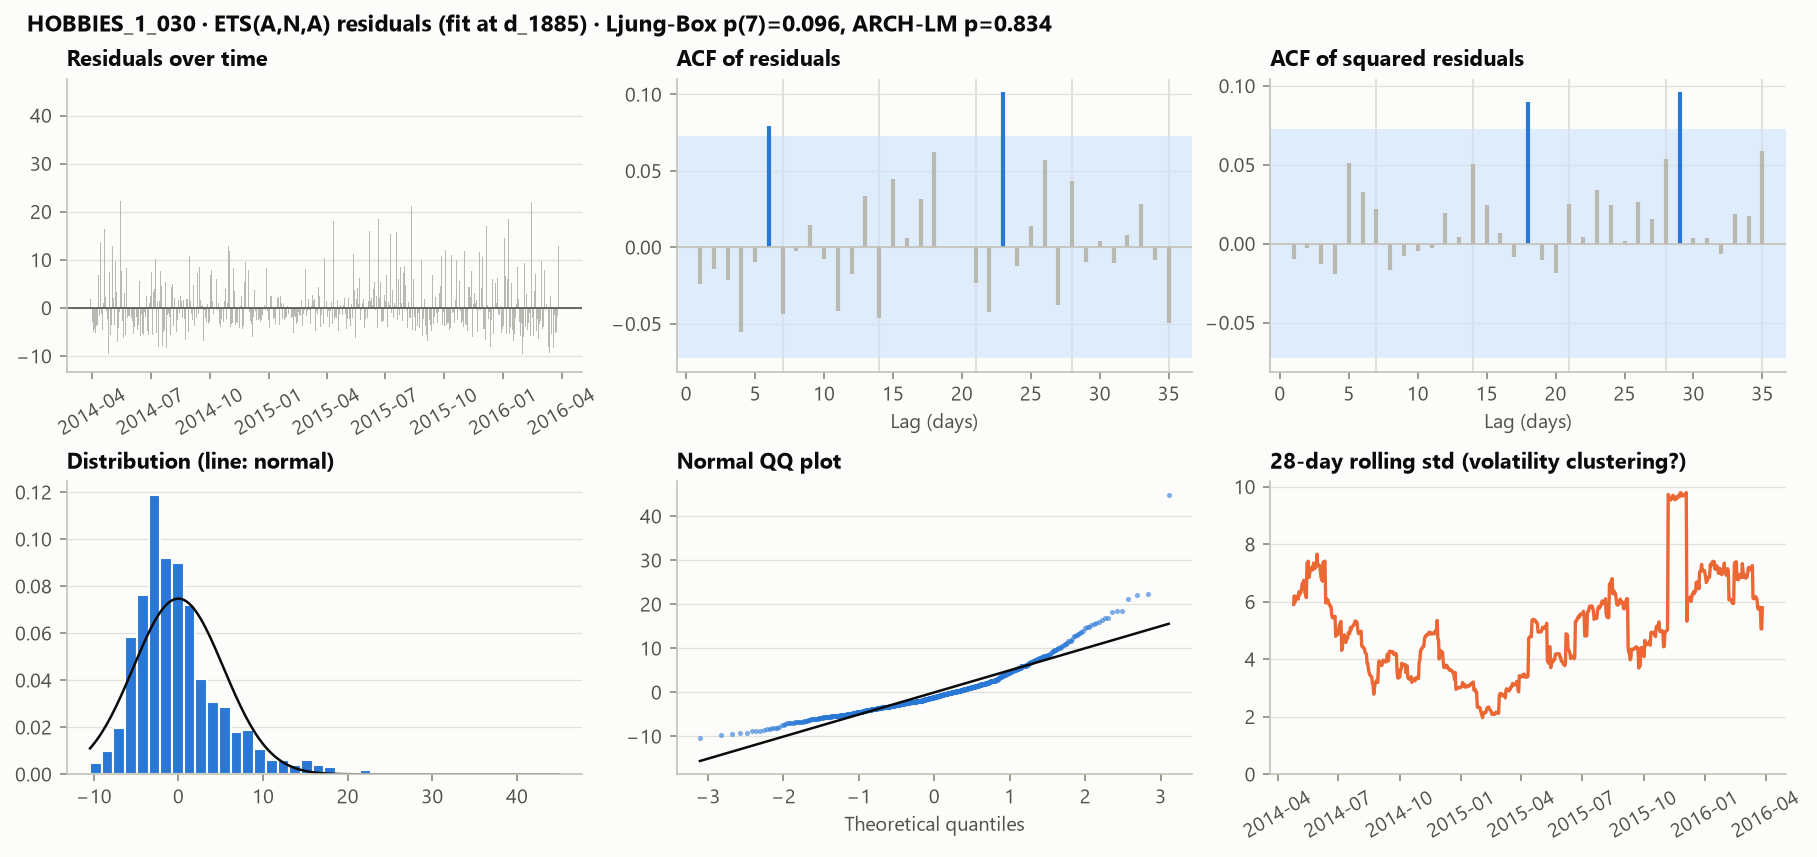

In [5]:
display(Image(filename=str(FIG / "HOBBIES_1_030_ets.png"), width=1100))

- A spiky product: most residuals are small, with occasional large positive spikes (excess kurtosis 8). The QQ plot bends sharply upward in the right tail.
- These spikes are **isolated**, not clustered: the squared-residual ACF is flat and ARCH-LM p = 0.83. Volatility is not predictable from recent volatility, so GARCH has nothing to model.
- For inventory, the issue here is the **heavy right tail**, which normal-theory safety stock underestimates. That is a distribution problem, not a volatility-clustering problem.

### FOODS_3_242 · SARIMA: intermittent, essentially white noise

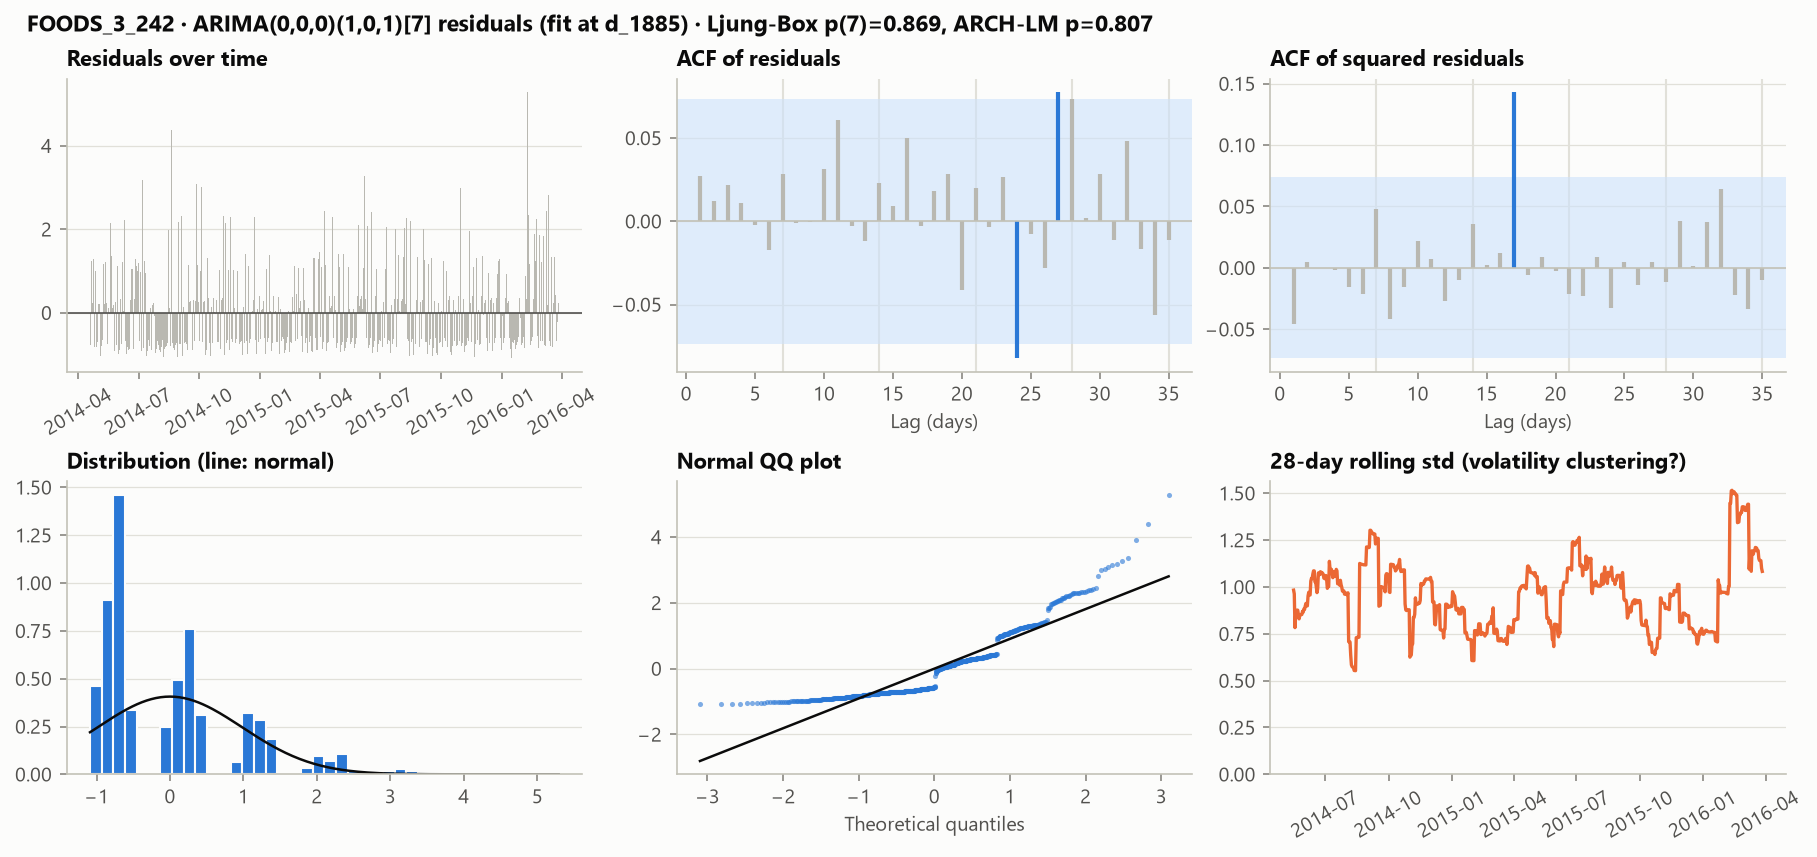

In [6]:
display(Image(filename=str(FIG / "FOODS_3_242_sarima.png"), width=1100))

- The residuals inherit the discreteness of the data (0, 1, 2, 3 units), visible as bands in the QQ plot.
- No autocorrelation (Ljung–Box p ≈ 0.87) and no ARCH effects: the model has extracted everything the history contains, consistent with the white-noise finding in notebook 02.

## 3. ARCH-LM test and the GARCH gate

In [7]:
print("ARCH-LM p-value, selected model, every origin:")
display(sel.pivot(index="item_id", columns="origin_d", values="arch_lm_p").loc[ITEMS]
        .style.format("{:.3f}").map(lambda v: "background-color:#f8d7d6" if v < 0.05 else ""))
gate = diag.groupby(["item_id", "model"]).agg(arch_effects=("arch_effects", "sum"), eligible=("garch_eligible", "sum"),
                                               zero_share=("zero_share", "mean")).reset_index()
display(gate.pivot(index="item_id", columns="model", values=["arch_effects", "eligible"]).loc[ITEMS])

ARCH-LM p-value, selected model, every origin:


origin_d,1800,1828,1856,1885
item_id,,,,
FOODS_3_586,0.002,0.006,0.012,0.020
HOUSEHOLD_1_447,0.076,0.036,0.046,0.000
FOODS_3_203,0.000,0.000,0.000,0.000
HOBBIES_1_189,0.060,0.054,0.062,0.058
HOBBIES_1_030,0.900,0.845,0.823,0.834
HOUSEHOLD_1_469,0.116,0.033,0.236,0.112
FOODS_3_242,0.242,0.381,0.899,0.807
HOUSEHOLD_1_046,0.795,0.897,0.897,0.890


arch_effects        eligible       
model                    ets sarima      ets sarima
item_id                                            
FOODS_3_586                4      4        4      4
HOUSEHOLD_1_447            3      1        3      1
FOODS_3_203                4      4        4      4
HOBBIES_1_189              0      3        0      3
HOBBIES_1_030              0      0        0      0
HOUSEHOLD_1_469            0      1        0      0
FOODS_3_242                0      0        0      0
HOUSEHOLD_1_046            0      0        0      0

- **For the selected models, ARCH effects appear only in the three highest-volume, near-continuous series**: FOODS_3_586, FOODS_3_203 and HOUSEHOLD_1_447.
- **Exceptions:**
  - HOBBIES_1_189 shows ARCH effects in its *SARIMA* residuals at 3 origins; its selected ETS model is borderline at p ≈ 0.06.
  - HOUSEHOLD_1_469 shows them at one SARIMA origin, but the gate excludes it because 43% of its days are zero.
- This matches the plan's expectation that GARCH may suit sparse, zero-heavy series poorly. On those series the volatility of a 0/1/2 count process is driven by whether a sale happens, which GARCH is not built to model.

## 4. GARCH(1,1) where the gate passed

In [8]:
cols = ["item_id", "model", "origin_d", "alpha", "alpha_p", "beta", "persistence", "valid", "var_ratio_h1",
        "cov80_const", "cov80_garch", "score80_const", "score80_garch", "score95_const", "score95_garch"]
display(garch[cols].sort_values(["item_id", "model", "origin_d"]).reset_index(drop=True))

,item_id,model,origin_d,alpha,alpha_p,beta,persistence,valid,var_ratio_h1,cov80_const,cov80_garch,score80_const,score80_garch,score95_const,score95_garch
0,FOODS_3_203,ets,1800,5.132e-02,0.032,0.842,0.893,True,1.017e+00,0.857,0.857,7.040,7.044,8.673,8.661
1,FOODS_3_203,ets,1828,4.614e-02,0.031,0.856,0.902,True,8.943e-01,0.893,0.857,7.919,7.893,8.916,8.869
2,FOODS_3_203,ets,1856,4.744e-02,0.025,0.851,0.898,True,8.699e-01,0.821,0.786,8.159,8.121,10.094,10.352
3,FOODS_3_203,ets,1885,5.003e-02,0.031,0.842,0.892,True,1.301e+00,0.821,0.821,9.188,9.285,12.574,12.331
4,FOODS_3_203,sarima,1800,5.008e-02,0.018,0.862,0.912,True,9.632e-01,0.893,0.893,6.886,6.868,11.299,11.251
5,FOODS_3_203,sarima,1828,4.730e-02,0.015,0.872,0.920,True,9.287e-01,0.893,0.893,7.802,7.765,11.902,11.724
6,FOODS_3_203,sarima,1856,4.616e-02,0.015,0.875,0.921,True,8.892e-01,0.821,0.821,8.557,8.489,13.855,13.945
7,FOODS_3_203,sarima,1885,4.695e-02,0.015,0.875,0.922,True,1.170e+00,0.857,0.857,8.384,8.483,10.734,11.067
8,FOODS_3_586,ets,1800,4.224e-02,0.090,0.934,0.976,True,1.087e+00,0.750,0.750,48.607,48.361,74.956,71.961
9,FOODS_3_586,ets,1828,4.137e-02,0.071,0.929,0.970,True,9.379e-01,0.893,0.857,38.888,38.637,58.296,58.750


In [9]:
cols = ["item_id", "model", "selected", "origins_garch_eligible", "garch_valid_fits", "score80_const", "score80_garch",
        "score95_const", "score95_garch", "score_gain_pct", "alpha_significant_share", "use_garch", "recommend_garch", "reason"]
d = decision[decision["origins_garch_eligible"] > 0][cols]
display(d.reset_index(drop=True))

,item_id,model,selected,origins_garch_eligible,garch_valid_fits,score80_const,score80_garch,score95_const,score95_garch,score_gain_pct,alpha_significant_share,use_garch,recommend_garch,reason
0,FOODS_3_203,ets,True,4,4.0,8.077,8.086,10.064,10.053,-6.337e-04,1.000,False,False,GARCH does not improve held-out interval scores
1,FOODS_3_203,sarima,False,4,4.0,7.908,7.901,11.947,11.996,-1.659e-01,1.000,False,False,GARCH does not improve held-out interval scores
2,FOODS_3_586,ets,True,4,4.0,36.913,36.244,56.130,54.451,2.402e+00,0.000,True,False,GARCH improves interval scores
3,FOODS_3_586,sarima,False,4,4.0,40.258,40.692,65.165,68.145,-2.826e+00,1.000,False,False,GARCH does not improve held-out interval scores
4,HOBBIES_1_189,sarima,False,3,3.0,31.507,40.239,45.675,105.166,-7.898e+01,0.000,False,False,GARCH does not improve held-out interval scores
5,HOUSEHOLD_1_447,ets,True,3,3.0,16.936,16.850,23.856,23.452,1.099e+00,0.333,True,False,GARCH improves interval scores
6,HOUSEHOLD_1_447,sarima,False,1,0.0,12.683,13.243,15.868,17.852,-8.458e+00,0.000,False,False,GARCH does not improve held-out interval scores


**What the GARCH fits show**

- **The ARCH coefficient α is very small (0.01–0.05).** It is not significant at 5% in any FOODS_3_586 fit and in only 1 of 3 HOUSEHOLD_1_447 fits. For FOODS_3_203 α *is* significant, yet GARCH still does not improve the held-out intervals: statistically detectable volatility clustering can be too weak to matter for forecasting. Nearly all the "memory" sits in β, with persistence 0.89–1.00. HOUSEHOLD_1_447 is close to an integrated GARCH (persistence ≈ 1), which signals a slowly drifting variance level more than genuine short-term clustering.
- **The predicted variance stays close to its long-run level**: the h = 1 ratio is 0.86–1.30. So GARCH changes the interval widths by only a few percent.
- **Held-out interval scores under the pre-specified rule** (keep GARCH only if both the 80% and 95% interval scores improve):
  - **FOODS_3_586 · ETS:** improves by 2.4% on average. Rule outcome: *use*.
  - **HOUSEHOLD_1_447 · ETS:** improves by 1.1%. Rule outcome: *use*.
  - **FOODS_3_203:** no improvement (a tie).
  - **SARIMA variants:** GARCH makes the intervals worse in every case, by up to 79% for HOBBIES_1_189. When it is wrong, it is badly wrong.
- **Stricter recommendation.** This criterion was added *after* inspecting the fits, and both outcomes are reported here. It requires α to be significant at most origins **and** a gain of at least 5%. **No product meets it.**

## 5. Decision

**GARCH is not added to the main pipeline.**

- The pre-specified rule technically favours GARCH for two ETS series. But the gains (1–2%) are within normal fold-to-fold variation, the ARCH coefficient is statistically insignificant, and in the comparable SARIMA fits GARCH degraded the intervals.
- Following the plan, *"a negative ARCH test is a valid scientific finding"*. The result is reported, and the extension is kept as an option rather than a default.
- **What matters more for inventory** is the **heavy right tail** of spiky and lumpy products (excess kurtosis 4–9), which makes normal-theory safety stock too small. M7 addresses this with Policy 2, which sizes safety stock from empirical quantiles of past forecast errors instead of a normal assumption.

## 6. Summary for the report

| Question | Answer |
|---|---|
| Unbiased residuals? | Yes: 32 of 32 selected fits |
| Leftover autocorrelation? | Statistically yes in about half the fits, practically small (largest |ACF| 0.096); a documented limitation |
| Normal residuals? | Near-normal only for FOODS_3_586; heavy tails for spiky and lumpy products (excess kurtosis 4–9), which matters for safety stock |
| ARCH effects? | Mainly in the 3 highest-volume continuous series (and HOBBIES_1_189 under SARIMA, where GARCH hurt) |
| GARCH useful? | No: insignificant α, ≤ 2.4% interval-score gain, sometimes much worse. Not adopted |